# 6.0 Trajectory Generation and Execution on the OMX

**ELEC3901 Robotic Manipulators, Lab 6** (week 6: Trajectory Planning and the Assignment)

<br>

Read before this lab: the week 6 lecture and RVC3 Ch. 3.1 to 3.3; Ch. 7.4. Each section below follows the lecture slides listed next to it.

### Contents

| Section | Where | Time | Lecture slides |
|---|---|---|---|
| [6.1 Path, trajectory and the quintic](#quintic) | desk | 10 min | 5-11: Path and trajectory; What a time scaling must do; The cubic; The quintic; Choosing T for the quintic |
| [6.2 The trapezoid, and what your servos do](#lspb) | desk | 8 min | 12-14, 22: The trapezoid (LSPB); Same limits, three scalings; Several joints: one shared s(t); What your servos do |
| [6.3 Via points three ways](#via) | desk | 7 min | 15-16: Via points; Via points on the Panda |
| [6.4 Joint space or Cartesian space](#cart) | desk | 10 min | 7, 17, 19-21: Straight in joint space or in task space; Cartesian motion; Joint space or Cartesian; On the OMX: a square on the mat |
| [6.5 On the arm: the servos' profile, measured](#profile) | arm | 15 min | 22: What your servos do |
| [6.6 On the arm: the square in the air](#square) | arm | 25 min | 21-22: On the OMX: a square on the mat; What your servos do |
| [6.7 On the arm: an approach, high then straight down](#approach) | arm | 15 min | 20: Joint space or Cartesian space; 24-25: the mini project's touch |
| [6.8 On the arm: via points, stop or blend](#viaarm) | arm | 20 min | 15-16: Via points; Via points on the Panda |
| [6.9 The whole lab with the toolbox](#tb) | desk | 5 min | 23: The Robotics Toolbox in practice |

**How this notebook works.** Each section gives the maths from the lecture, a worked case in code, then the next case for you to
write: a *Task* (a function, checked against hidden values) or an *Exercise* (a few lines with `...` blanks, checked against the
toolbox by `try_it`, which prints `OK` or what looks wrong). Each section ends with the same result from `spatialmath`, the way you
will usually do it. *Desk* sections need no arm: do them before the session if you can. Anything marked **(Optional)** is for
when the core is done: skip it if you are short of time. A **Hint** opens when you click it - try without it first.

*Notation.* $q(t)$ is a joint angle as a function of time, $\dot q$ and $\ddot q$ its velocity and acceleration. A move goes from
$q_0$ to $q_f$ in $T$ seconds; $D = q_f - q_0$ is its distance and $s = t/T$ runs from 0 to 1. $V$ and $A$ are a joint's speed and
acceleration limits. Positions on the mat are in the mat frame {M}, as in Labs 2-5. Lengths in the text are millimetres; the code works
in metres and radians. Equations are numbered (1), (2), ... through the notebook.

**Checkpoint for sign-off:** The printed checkpoint line: the planned move time and the measured cruise speed against the plan, each square's largest deviation, the descents' sideways drift, and the via points stopping against blending (time and closest approach)

Reference versions of previous weeks' tasks are imported from `omx_ref.py`, so last week never blocks this week; the functions you
write here are the ones your assignment will be built from.

> **Safety.** Keep the workspace clear of hands and cables before enabling torque, and set a conservative profile velocity
> (`arm.set_profile(60, 20)` or lower) before commanding motion. If anything unexpected happens, press the power isolator on the
> bench first, then think. Torque off (`arm.torque(False)`) before touching the arm.

The imports for this notebook. Section 6.5 connects to the arm; nothing before it needs the arm. This lab does not use the camera.

In [ ]:
import sys, os
# Repository layout: weekNN/ (notebooks), scripts/ (helper modules), data/ (your measurements, shared by every week).
for _up in ('.', '..', os.path.join('..', '..')):
    if os.path.isdir(os.path.join(_up, 'scripts')):
        _root = os.path.abspath(_up); sys.path.insert(0, os.path.join(_root, 'scripts'))
        os.makedirs(os.path.join(_root, 'data'), exist_ok=True); os.chdir(os.path.join(_root, 'data'))   # files save/load here
        break
import numpy as np, matplotlib.pyplot as plt, time, cv2
import roboticstoolbox as rtb
from spatialmath import SE3, SO3, SE2, UnitQuaternion
from spatialmath.base import trplot, tranimate
from omx_model import omx_robot, omx_ik, Q_LIM, T_EC, P_TIP_E, mount_tilt, look_down_pitch
from omx import OMX
from omx_camera import Camera, tip_in_mat, predicted_T_CM, pose_error
from omx_calib import small_T
from labcheck import check, try_it
NOM = dict(d1=0.0975, l2z=0.11315, l2x=0.0415, l3=0.162, l4=0.123)   # nominal link parameters (m)
from omx_ref import R_to_rpy, camera_ik, chain_T_BM, condition_number, dh_table, error_stats, fk_dh, inv_T, jacobian_numeric, make_T, manipulability, mount_from_views, omx_fk, omx_ik, planar_2r, plot_error_field, revolute_jacobian, rot2, rot_about, rotx, roty, rotz, rpy_to_R, se2, static_torque, step_log, transform_point, transform_points, transl2, trot2   # reference versions of PREVIOUS labs' tasks; your own definitions below override them
np.set_printoptions(precision=4, suppress=True)
%matplotlib inline
omx = omx_robot()              # Robotics Toolbox model (nominal)
T_EC_CAD = T_EC   # the design camera mount (ROBOTIS CAD: optical axis 38 deg below the tool). Each arm's camera sits a little differently: Lab 2
                  # measures yours, and from Lab 3 on the MOUNT cell re-measures it every session and replaces T_EC
HOVER = 0.09      # tip hover height with the tool vertical: the OMX-F reaches r ~ 0.24 m there (touching the mat: r ~ 0.28 m)
CAM_HOVER = 0.15  # tip height for camera measurements, tool pitched with look_down_pitch(T_EC) so the camera looks straight down:
                  # the camera is then ~180 mm up, enough to see the marker ring around the clear zone

In [ ]:
from omx import profile_times, VEL_UNIT_RAD_S, ACC_UNIT_RAD_S2, HOME_Q    # the servos' shared trapezoid (Section 6.2)
from omx_camera import load_mat
import json, os
if os.path.exists('lab2_refs.json'):
    T_BM = SE3(np.array(json.load(open('lab2_refs.json'))['T_BM']))
    print('T_BM from lab2_refs.json (your Lab 2 bench)')
else:
    T_BM = SE3()
    print('no lab2_refs.json in data/ (Lab 2 Section 2.6 writes it): the mat is taken as nominal, T_BM = I')

def ik_mat(p, pitch):
    # IK for a point given in the mat frame {M}
    p_B = (T_BM * np.asarray(p, float)).ravel()
    return omx_ik(p_B, pitch)

def tip_in_M(q):
    # the tool tip in the mat frame, for one joint vector or for N x 4 joint vectors (-> N x 3)
    P_B = omx.fkine(q).t
    return (T_BM.inv() * P_B.T).T

def down_pose(x, y, z):
    # the tool pointing down with its tip at (x, y, z) in the mat frame, as an SE3 pose
    return SE3(x, y, z) * SE3.Ry(np.pi / 2)

def ik_pose(T):
    # IK for a tool pose T in the mat frame: its position, and its pitch from the tool's x axis (nose down positive)
    pitch = -np.arcsin(T.R[2, 0])
    return ik_mat(T.t, pitch)

<br>

<a id='quintic'></a>

### 6.1 Path, trajectory and the quintic (desk)
---

A **path** is where the arm goes; a **trajectory** is the path with time attached (lecture slide 5). For one joint going from $q_0$ to
$q_f$, a move that starts and ends at rest, with no jump in acceleration (slide 8), needs six conditions:

$$ q(0) = q_0,\quad \dot q(0) = 0,\quad \ddot q(0) = 0, \qquad q(T) = q_f,\quad \dot q(T) = 0,\quad \ddot q(T) = 0 \qquad (1) $$

Six conditions need six unknowns: a quintic, $q(t) = a_0 + a_1 t + a_2 t^2 + a_3 t^3 + a_4 t^4 + a_5 t^5$. The three conditions at
$t = 0$ give $a_0 = q_0$ and $a_1 = a_2 = 0$; the three at $t = T$ give the rest (slide 10). With $s = t/T$ and $D = q_f - q_0$:

$$ q(t) = q_0 + D\,(10 s^3 - 15 s^4 + 6 s^5), \qquad \dot q = \frac{D}{T}(30 s^2 - 60 s^3 + 30 s^4), \qquad
   \ddot q = \frac{D}{T^2}(60 s - 180 s^2 + 120 s^3) \qquad (2) $$

The velocity peaks half way and the acceleration at $s = \tfrac12 \mp \tfrac{\sqrt3}{6}$ (slide 11):

$$ \dot q_{\max} = \frac{15}{8}\,\frac{D}{T}, \qquad |\ddot q|_{\max} = \frac{10}{\sqrt3}\,\frac{D}{T^2} \approx 5.77\,\frac{D}{T^2} \qquad (3) $$

so the shortest quintic that keeps a joint within its speed limit $V$ and acceleration limit $A$ takes

$$ T = \max\left(\frac{15\,D}{8\,V},\ \sqrt{\frac{5.77\,D}{A}}\right) \qquad (4) $$

You will not code (2): the toolbox has it. `rtb.quintic(q0, qf, t)` is the quintic for one joint, and `rtb.jtraj(q0, qf, t)` the same
for a joint vector; `.q`, `.qd` and `.qdd` hold the samples, one row per time. What the toolbox cannot know is your arm's limits:
choosing $T$ is your job.

In [ ]:
# --- worked case: the toolbox's quintic for four joints, 2 s, and the peaks of equation (3) --------------------------------
t = np.linspace(0, 2, 101)
q0 = np.array([0, 0.2, 0.3, -0.5])
qf = np.array([0.8, 0.8, -0.4, 0.6])
tj = rtb.jtraj(q0, qf, t)
D = np.abs(qf - q0)
print('peak speeds, jtraj (rad/s):           ', np.round(np.abs(tj.qd).max(axis=0), 3))
print('equation (3), 15 D / (8 T):           ', np.round(15 * D / (8 * 2.0), 3))
print('peak accelerations, jtraj (rad/s^2):  ', np.round(np.abs(tj.qdd).max(axis=0), 3))
print('equation (3), 5.77 D / T^2:           ', np.round(5.77 * D / 2.0**2, 3))
fig, ax = plt.subplots(1, 3, figsize=(12, 3))
for a_, y, name in zip(ax, (tj.q, tj.qd, tj.qdd), ('q (rad)', 'qd (rad/s)', 'qdd (rad/s^2)')):
    a_.plot(t, y)
    a_.set_title(name)
    a_.set_xlabel('t (s)')
    a_.grid(alpha=0.3)
ax[0].legend(['joint 1', 'joint 2', 'joint 3', 'joint 4'], fontsize=8)
plt.tight_layout()
plt.show()

**Your turn: the lecture's worked case, with the toolbox.** One OMX joint turns 60°, within the limits the labs use, `set_profile(40, 10)`: the servos'
units are 0.229 rpm for speed (`VEL_UNIT_RAD_S` rad/s each) and 214.577 rev/min² for acceleration (`ACC_UNIT_RAD_S2` rad/s² each).

In [ ]:
# --- Exercise 6.1a: the shortest quintic within the limits, equation (4) --------------------------------------------
D60 = np.radians(60)
V = 40 * VEL_UNIT_RAD_S            # rad/s
A = 10 * ACC_UNIT_RAD_S2           # rad/s^2
T_quintic = ...                    # equation (4), s
# another way: the shortest T on a 1 ms grid whose sampled quintic stays within both limits
_T = next(Tg for Tg in np.arange(0.5, 4, 0.001) if np.abs(rtb.quintic(0, D60, np.linspace(0, Tg, 2001)).qd).max() <= V + 1e-9
          and np.abs(rtb.quintic(0, D60, np.linspace(0, Tg, 2001)).qdd).max() <= A + 1e-9)
try_it('shortest quintic (s)', T_quintic, _T, tol=2e-3);

<details><summary><b>Hint</b></summary>

$D$ in radians, $V$ in rad/s and $A$ in rad/s²: the two candidates are `15 * D60 / (8 * V)` and `np.sqrt(5.77 * D60 / A)`; the move
must satisfy both limits, so take the larger. The lecture's slide 11 has the same numbers.

</details>

<br>

<a id='lspb'></a>

### 6.2 The trapezoid, and what your servos do (desk)
---

A **trapezoid** (linear segment with parabolic blends, LSPB; slide 12) uses the limits directly: it accelerates at $A$ for a ramp time
$t_a$, cruises at $V$, then brakes. The area under the speed curve is the distance, so

$$ t_a = \frac{V}{A}, \qquad D = V\,(T - t_a) \quad\Rightarrow\quad T = \frac{D}{V} + \frac{V}{A} \qquad (5) $$

If the move is too short to reach $V$ ($D < V^2/A$) there is no cruise, only a triangle: $T = 2\sqrt{D/A}$. Within the same limits the
trapezoid finishes first (slide 13), at the price of jumps in acceleration at its four corners.

**Several joints** move on one shared time scaling (slide 14): every joint is its start plus $s(t)$ times its own distance,

$$ q_j(t) = q_{0,j} + s(t)\,(q_{f,j} - q_{0,j}) \qquad (6) $$

so they start and arrive together, and the joint that needs longest sets $T$. **This is what your servos do** (slide 22): since
30 October the OMX runs a time-based profile. `arm.set_profile(V, A)` sets the limits; on every `arm.move_q(q)` the joint with the
furthest to go runs the trapezoid (5), and every other joint is given the same $T$ and $t_a$, scaled to its own distance. The function
`profile_times(D, V, A)` in `omx.py` is what `move_q` uses.

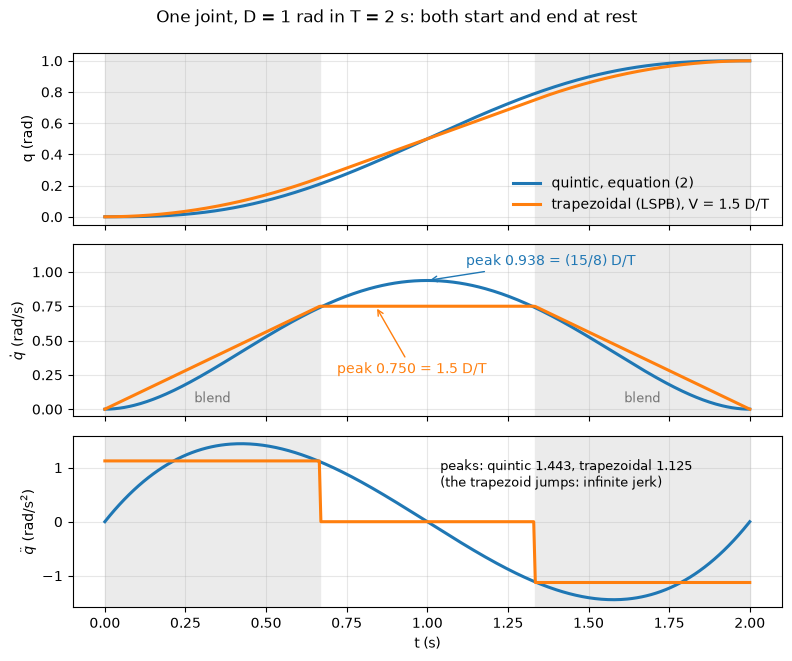

*The same move, D = 1 rad in T = 2 s. The trapezoid's peak velocity and peak acceleration are both lower than the
    quintic's, but its acceleration jumps at the ends of the ramps: the quintic is smoother, the trapezoid faster for a given speed limit.*

In [ ]:
# --- worked case: the toolbox's trapezoid for D = 1 rad in T = 2 s ------------------------------------------------------
# rtb.trapezoidal picks V = 1.5 D / T unless told otherwise; then t_a = T - D / V from (5), and A = V / t_a
t2 = np.linspace(0, 2, 2001)
tr = rtb.trapezoidal(0.0, 1.0, t2)
V_tb = 1.5 * 1.0 / 2.0
ta_tb = 2.0 - 1.0 / V_tb
print(f'equation (5): V = {V_tb:.3f} rad/s, t_a = {ta_tb:.3f} s, A = {V_tb / ta_tb:.3f} rad/s^2')
print(f'the toolbox:  V = {tr.qd.max():.3f} rad/s, t_a = {tr.tblend:.3f} s, A = {tr.qdd.max():.3f} rad/s^2')

**The move you will make on the arm in Section 6.5**: from home to `Q_GOAL6`, all four joints at once, `set_profile(40, 10)`. Work out
what the servos will do: the shared move time, and each joint's top speed.

In [ ]:
Q_GOAL6 = HOME_Q + np.radians([60.0, 10.0, -15.0, 5.0])     # home turned 60 deg about the base, the arm a little lower
D_move = Q_GOAL6 - HOME_Q
print('each joint moves (deg):', np.round(np.degrees(D_move), 1))
print('tip at home and at the goal (mm, base frame):', np.round(1e3 * omx.fkine(HOME_Q).t), np.round(1e3 * omx.fkine(Q_GOAL6).t))

In [ ]:
# --- Exercise 6.2a: the servos' shared trapezoid for that move --------------------------------------------------------
k_far = ...                        # the joint (0..3) with the furthest to go
T_move = ...                       # the shared move time: equation (5) for that joint, s
ta_move = ...                      # the shared ramp time, s
v_top = ...                        # each joint's top speed on the shared profile, deg/s (4,): its distance over T - t_a
_T, _ta = profile_times(D_move, np.full(4, V), np.full(4, A))
try_it('the furthest joint', k_far, int(np.argmax(np.abs(D_move))))
try_it('shared move time (s)', T_move, _T, tol=1e-9)
try_it('top speeds (deg/s)', v_top, np.degrees(np.abs(D_move) / (_T - _ta)), tol=1e-6);

<details><summary><b>Hint</b></summary>

The furthest joint runs its own trapezoid, so (5) with its distance gives $T$ and $t_a = V/A$. Every joint uses the same $T$ and
$t_a$ (equation (6)), so joint $j$'s cruise speed is $|D_j| / (T - t_a)$: the area of its trapezoid must be its own distance.

</details>

<br>

<a id='via'></a>

### 6.3 Via points three ways (desk)
---

A pick-and-place passes through several **via points**: above the part, down to it, up, across, down, up (slide 15). Three ways
through them:

* **Stop at each via point:** simple and safe, but slow, and the arm jolts at every one.
* **Velocities at the via points** (piecewise polynomials, Lynch & Park Fig. 9.7): choose a velocity at each via point and join the
  segments; the path goes through every via point. `rtb.jtraj(q_a, q_b, t, qd0, qd1)` per segment.
* **Linear segments with parabolic blends** (LSPB): straight segments joined by constant-acceleration blends of `tacc` seconds; smooth,
  but it **cuts the corners**. `rtb.mstraj(vias, dt, tacc, qdmax)`, which times each segment by its slowest joint:

$$ T_k = \max_j \frac{|q_{j,k+1} - q_{j,k}|}{\dot q_{\max}} \qquad (7) $$

In [ ]:
# --- worked case: pick-and-place via points on the mat (tool pointing down), mstraj with no blends ----------------------
VIA_M = [[0.14, -0.05, 0.05], [0.14, -0.05, 0.0], [0.14, -0.05, 0.05],        # above the pick, the pick, above it again
         [0.20, 0.05, 0.05], [0.20, 0.05, 0.0], [0.20, 0.05, 0.05]]           # above the place, the place, above it again
via = []
for p in VIA_M:
    via.append(ik_mat(p, np.pi / 2))
via = np.array(via)
QD_MAX = np.radians(60)
tr0 = rtb.mstraj(via, dt=0.05, tacc=0.0, qdmax=QD_MAX)
# mstraj leaves the start out (its first sample is one dt along): put it back, so t = 0 is via[0] and tr0.arrive lines up
t_all = np.concatenate([[0.0], tr0.t + 0.05])
q_all = np.vstack([via[0], tr0.q])
t_via = np.concatenate([[0.0], tr0.arrive])
print(f'no blends: {t_all[-1]:.2f} s, {len(t_all)} samples; at the via points at t =', np.round(t_via, 2))
plt.figure(figsize=(8, 3))
plt.plot(t_all, np.degrees(q_all), '.-', ms=4)
plt.plot(t_via, np.degrees(via), 'ko', mfc='none')                              # the via points
plt.xlabel('t (s)')
plt.ylabel('q (deg)')
plt.legend(['joint 1', 'joint 2', 'joint 3', 'joint 4', 'via points'], fontsize=8)
plt.grid(alpha=0.3)
plt.show()

**Your turn: blend the corners**, `tacc = 0.3` s, and measure how close the tool comes to the pick point `VIA_M[1]`.

In [ ]:
# --- Exercise 6.3a: blends cut corners ------------------------------------------------------------------------------
tr_b = rtb.mstraj(via, dt=0.05, tacc=0.3, qdmax=QD_MAX)
tips_b = ...                       # the tool tip at every sample, in the mat frame (N x 3): tip_in_M
miss_mm = ...                      # the closest the tip comes to VIA_M[1], mm
_tips = np.array([(T_BM.inv() * SE3(omx_fk(qq))).t for qq in tr_b.q])          # the tips another way
try_it('closest approach to the pick point (mm)', miss_mm, 1e3 * np.linalg.norm(_tips - VIA_M[1], axis=1).min(), tol=1e-3);

**Your turn: a velocity at a via point.** Go from above the pick (`via[0]`) down to the pick (`via[1]`) and arrive still moving
downwards, then carry on. Choose the joint velocity at the pick as a fraction of the next segment's direction.

In [ ]:
# --- Exercise 6.3b: through a via point at a chosen velocity (jtraj with qd0, qd1) -------------------------------------
t1 = np.linspace(0, 1.0, 51)
v_pick = 0.4 * (via[2] - via[1])   # a chosen joint velocity at the pick (rad/s)
seg1 = ...                         # rtb.jtraj from via[0] to via[1], arriving at v_pick
seg2 = ...                         # rtb.jtraj from via[1] to via[2], leaving at v_pick
gap_deg = ...                      # how far seg1 ends from via[1], the largest joint difference, deg
try_it('arrives at the pick moving at v_pick', lambda: seg1.qd[-1], v_pick, tol=1e-9)
try_it('the second segment leaves at v_pick', lambda: seg2.qd[0], v_pick, tol=1e-9)
try_it('gap at the via point (deg)', gap_deg, 0.0, tol=1e-6);

<details><summary><b>Hint</b></summary>

`rtb.jtraj(qa, qb, t, qd0=..., qd1=...)` sets the joint velocity at the start and the end of a segment; the end of one segment and the
start of the next must share the same velocity, or the arm jolts there. A real pick would arrive at rest: here the via point is one the
arm passes through.

</details>

<br>

<a id='cart'></a>

### 6.4 Joint space or Cartesian space (desk)
---

Interpolating the joints (`jtraj`, or the servos' own `move_q`) is cheap and stays inside the joint limits if both ends do, but the tool
does not move in a straight line (slides 7 and 20). To move the tool along a straight line, interpolate the **position** and solve the
IK at every sample (slide 17):

$$ \mathbf{p}(s) = (1 - s)\,\mathbf{p}_a + s\,\mathbf{p}_b, \qquad q(s) = \mathrm{IK}\big(\mathbf{p}(s), \theta\big),
   \qquad s \in [0, 1] \qquad (8) $$

with the tool pitch $\theta$ held ($\pi/2$: the tool pointing down). Each sample can fail (out of reach), and near a singularity small
steps in $\mathbf{p}$ need large steps in $q$ (slide 18). The toolbox does (8) for whole poses: `rtb.ctraj(T0, T1, s=...)` returns
the poses along the straight line from `T0` to `T1`, the orientation interpolated too (slide 23). The square below is the
lecture's (slide 21): 80 mm, 20 mm above the mat.

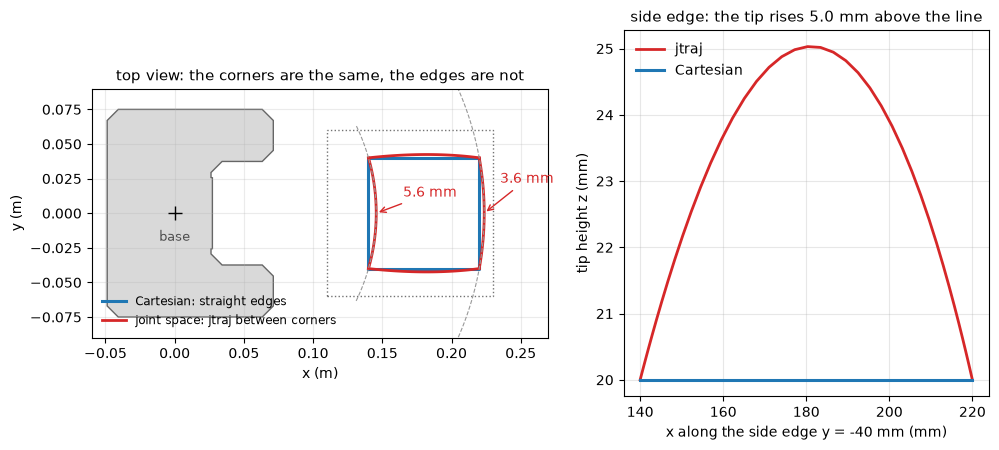

*The lecture's square, 20 mm above the mat with the tool pointing down. Interpolating the joints between the same
    corners gives arcs about the base (dashed circles) and, along the side edges, the tip rises above the line.*

In [ ]:
CORNERS = [(0.14, -0.04), (0.22, -0.04), (0.22, 0.04), (0.14, 0.04), (0.14, -0.04)]     # mat frame (m), the lecture's square
Z_AIR = 0.02                                                                            # 20 mm above the mat
# --- worked case: the far edge, (220, -40) to (220, 40) mm: the poses on the straight line, and jtraj between its ends -----
T0 = down_pose(0.22, -0.04, Z_AIR)
T1 = down_pose(0.22, 0.04, Z_AIR)
poses = rtb.ctraj(T0, T1, s=np.linspace(0, 1, 25))      # evenly spaced s, as in (8) (an integer count would use a trapezoid)
print('ctraj: 25 poses; the tip at the start, the middle and the end (mm):')
print(np.round(1e3 * np.array([poses[0].t, poses[12].t, poses[24].t]), 1))
q_jnt = rtb.jtraj(ik_pose(T0), ik_pose(T1), 25).q          # the joints interpolated instead
p_jnt = tip_in_M(q_jnt)
print(f'jtraj between the same ends: x along the edge from {1e3 * p_jnt[:, 0].min():.1f} to {1e3 * p_jnt[:, 0].max():.1f} mm '
      '(straight: 220): the tip swings out on an arc about the base')

**Your turn: the task.** Turn the poses into joint angles, one IK per pose: a straight line the arm can stream. `ik_pose(T)`, given
in the imports cell, is the IK for a pose in the mat frame.

### Task 1 — A straight line in joint angles
Write `straight_line_joints(T0, T1, n, ik)`: the tool moving in a straight line from pose `T0` to pose `T1` (`SE3`), in `n` equal steps,
as joint angles. `rtb.ctraj(T0, T1, s=...)` gives the poses along the line (equation (8)); `ik(T)` turns one pose into joint angles, or
`None` when it is out of reach. Return an `(n + 1) x 4` array; raise `ValueError` if a pose is out of reach.

In [ ]:
def straight_line_joints(T0, T1, n, ik):
    """The tool on a straight line from pose T0 to pose T1 in n steps -> (n + 1) x 4 joint angles, ik(T) at every pose."""
    # TODO: write your implementation here, one step under each comment

    # the poses along the line, evenly spaced: s from 0 to 1 in n steps (ctraj interpolates the position and the orientation)

    # a list for the joint angles, one row per pose

    # the joint angles for each pose, from the IK; None means out of reach

    raise NotImplementedError   # delete this line when your code is complete


In [ ]:
# --- self-check (hidden expected values) ---------------------------------------------------------
check('one edge of the square, 8 steps', lambda: straight_line_joints(SE3(0.14, -0.04, 0.02) * SE3.Ry(np.pi / 2), SE3(0.22, -0.04, 0.02) * SE3.Ry(np.pi / 2), 8, lambda T: omx_ik(T.t, -np.arcsin(T.R[2, 0]))), '4642ca925f', decimals=4)
check('a descent, 80 to 25 mm: the tip at the start, the middle and the end', lambda: [omx_fk(q)[:3, 3] for q in straight_line_joints(SE3(0.17, 0.08, 0.08) * SE3.Ry(np.pi / 2), SE3(0.17, 0.08, 0.025) * SE3.Ry(np.pi / 2), 10, lambda T: omx_ik(T.t, -np.arcsin(T.R[2, 0])))[[0, 5, 10]]], '7ad4b17012', decimals=5);

<details><summary><b>Hint</b></summary>

`rtb.ctraj(T0, T1, s=np.linspace(0, 1, n + 1))` gives `n + 1` poses; a `for` loop over them gives one pose at a time. `ik(T)` returns
`None` when the pose is out of reach: raise `ValueError` then, so nothing unreachable is ever sent to the arm.

</details>

In [ ]:
def square_joints(z, n_per_edge):
    # given: the square at height z, edge by edge with your straight_line_joints (each edge starts where the last one ended)
    q = [ik_pose(down_pose(*CORNERS[0], z))]
    for k in range(4):
        Ta = down_pose(*CORNERS[k], z)
        Tb = down_pose(*CORNERS[k + 1], z)
        try:
            edge = straight_line_joints(Ta, Tb, n_per_edge, ik_pose)
        except NotImplementedError:                       # Task 6.1 not done yet: the edge, given, so the lab can go on
            edge = []
            for si in np.linspace(0, 1, n_per_edge + 1):
                edge.append(ik_mat((1 - si) * Ta.t + si * Tb.t, np.pi / 2))
        q.extend(edge[1:])
    return np.array(q)

# the whole square both ways: straight edges (yours) and jtraj between the corner configurations
q_corners = []
for x, y in CORNERS:
    q_corners.append(ik_pose(down_pose(x, y, Z_AIR)))
q_corners = np.array(q_corners)
q_joint = [q_corners[0]]
for k in range(4):
    q_joint.extend(rtb.jtraj(q_corners[k], q_corners[k + 1], 26).q[1:])
q_joint = np.array(q_joint)
q_cart = square_joints(Z_AIR, 25)
p_joint = tip_in_M(q_joint)
p_cart = tip_in_M(q_cart)
plt.figure(figsize=(5, 5))
plt.plot(p_cart[:, 0], p_cart[:, 1], 'b', label='Cartesian (ctraj + IK)')
plt.plot(p_joint[:, 0], p_joint[:, 1], 'r', label='jtraj between corners')
plt.axis('equal')
plt.legend()
plt.grid(alpha=0.3)
plt.title('the tip, top view (mat frame)')
plt.show()
print(q_cart.shape, q_joint.shape, '- the same number of samples, so both take the same time when streamed')

In [ ]:
# --- Exercise 6.4a: how far does the joint-space tip leave the 20 mm line? ------------------------------------------
rise_mm = ...                      # the highest point of p_joint above Z_AIR, mm
_z = np.array([(T_BM.inv() * SE3(omx_fk(qq))).t[2] for qq in q_joint])
try_it('rise above the line (mm)', rise_mm, 1e3 * (_z.max() - Z_AIR), tol=1e-3);

<br>

<a id='profile'></a>

### 6.5 On the arm: the servos' profile, measured (arm)
---

From here on you need the arm, or the digital twin (`SIMULATE = True` in the next cell). Connect; the camera is not needed.

The move of Exercise 6.2a, home to `Q_GOAL6` at `set_profile(40, 10)`, with the joint angles logged as fast as the bus allows. You worked
out what the servos should do; now measure what they do.

In [ ]:
# --- connect to the arm --------------------------------------------------------------------------------------------
# Safe to re-run: an existing connection is closed first, so the COM port is released before it is opened again.
# SIMULATE = True runs the MuJoCo digital twin (omx_mujoco.py) instead of the real arm: same API, a rendered
# wrist camera, and optional hidden model errors so you can test calibration against ground truth.
SIMULATE = False
PORT = 'auto'                  # finds the OpenRB-150 by its USB id; or set it, e.g. 'COM4' (Device Manager) / '/dev/ttyACM0'
# --- which arm are you on today? Read the asset label on the base. Everything you measure is tagged with it,
#     because zero offsets, camera intrinsics and the camera mount are all properties of THIS arm.
ARM_ID = 'OMX-00'            # EDIT every session
if 'arm' in globals():
    try:
        arm.close()
    except Exception as e:
        print('closing the previous connection:', e)
    del arm
if SIMULATE:
    from omx_mujoco import OMXSim, SimCamera
    arm = OMXSim(view=True)    # view=False if no display; set kin_error=..., joint_offsets=... to hide errors
    # Video: arm.record('run.mp4') writes the wrist camera and a scene camera side by side (same size) while the arm
    # moves; arm.stop_recording() when done.
else:
    arm = OMX(PORT)
print('connected:', 'digital twin' if SIMULATE else arm.port_name, '| arm', ARM_ID)

In [ ]:
def log_move(arm, q_goal, duration):
    # given: send one goal, then read the joints as fast as the bus allows for `duration` s -> (t, q): times (N,), angles (N x 4)
    log_t, log_q = [], []
    t0 = time.time()
    arm.move_q(q_goal)
    while time.time() - t0 < duration:
        log_q.append(arm.read_q())
        log_t.append(time.time() - t0)
        time.sleep(0.004)                          # about the bus's own rate: a reading every few ms
    return np.array(log_t), np.array(log_q)

def stream_logged(arm, qs, dt, settle=0.5):
    # given: arm.stream(qs, dt), then keep reading for `settle` s while the arm catches up with the last sample.
    # -> (t, q) logged during the stream (one reading per sample, for Task 6.3) and (t_all, q_all) for the whole motion
    t_s, q_s = arm.stream(qs, dt)
    t_e, q_e = log_move(arm, qs[-1], settle)
    t_all = np.concatenate([t_s, t_s[-1] + dt + t_e])
    q_all = np.vstack([q_s, q_e])
    return t_s, q_s, t_all, q_all

V40, A10 = 40 * VEL_UNIT_RAD_S, 10 * ACC_UNIT_RAD_S2            # set_profile(40, 10) in rad/s and rad/s^2
T_plan, ta_plan = profile_times(Q_GOAL6 - HOME_Q, np.full(4, V40), np.full(4, A10))   # what move_q will send (Exercise 6.2a)
arm.torque(True)
arm.set_profile(40, 10)
arm.home(wait=True)
time.sleep(0.5)
t_log, q_log = log_move(arm, Q_GOAL6, T_plan + 1.0)
np.save('lab6_profile_log.npy', np.column_stack([t_log, q_log]))
arm.home(wait=True)
print(f'{len(t_log)} readings in {t_log[-1]:.2f} s ({len(t_log) / t_log[-1]:.0f} per second); saved lab6_profile_log.npy')
plt.figure(figsize=(8, 3))
plt.plot(t_log, np.degrees(q_log - q_log[0]))
plt.axvline(T_plan, color='k', ls='--', lw=0.8)
plt.xlabel('t (s)')
plt.ylabel('q - q(0) (deg)')
plt.legend(['joint 1', 'joint 2', 'joint 3', 'joint 4', f'the planned T ({T_plan:.2f} s)'], fontsize=8)
plt.grid(alpha=0.3)
plt.show()

**Your turn: the task. Read the move off the log.** For each joint, when has it covered 90 % of its distance? And how fast did the
furthest joint cruise? Single readings are noisy, so the cruise speed is the median of its speeds while it is between 30 % and 70 %
of its travel, not the largest one. Gravity can leave a joint a degree or two short of its goal (Lab 4), which is why the times are
taken at 90 %.

### Task 2 — A move, measured
Write `move_metrics(t, q, D)` for a logged move: `t` the reading times (N,), `q` the joint angles read (N x 4), `D` each joint's distance
(rad). Return `(t90, v_cruise)`: for each joint the first time it has covered 90 % of its distance (s, 4 values), and the furthest
joint's **cruise speed** (deg/s): the median of its speeds between consecutive readings while it is between 30 % and 70 % of its travel.
Section 6.5 uses it on your arm's move: do the joints arrive together, and at the speed the servos planned?

In [ ]:
def move_metrics(t, q, D):
    """A logged move: times t (N,), joint angles q (N x 4), distances D (rad) -> (t90 (4,) s, cruise speed of the furthest joint, deg/s)."""
    # TODO: write your implementation here, one step under each comment

    # how far each joint has moved at each reading (N x 4)

    # for each joint, the first reading at or past 90 % of its distance, and its time

    # the joint with the furthest to go

    # its speed between consecutive readings, deg/s

    # its cruise: the median speed while it is between 30 % and 70 % of its travel

    raise NotImplementedError   # delete this line when your code is complete


In [ ]:
# --- self-check (hidden expected values) ---------------------------------------------------------
check('t90 on a canned move', lambda: (lambda t, D: move_metrics(t, np.outer(10 * (t / 2)**3 - 15 * (t / 2)**4 + 6 * (t / 2)**5, D), D))(np.linspace(0, 2, 201), np.array([0.5, -0.2, 0.3, 0.1]))[0], '0ccfa6c9c9', decimals=4)
check('cruise speed on a canned move', lambda: (lambda t, D: move_metrics(t, np.outer(10 * (t / 2)**3 - 15 * (t / 2)**4 + 6 * (t / 2)**5, D), D))(np.linspace(0, 2, 201), np.array([0.5, -0.2, 0.3, 0.1]))[1], '71f0da05eb', decimals=3);

<details><summary><b>Hint</b></summary>

`moved[:, j] / D[j]` runs from 0 to about 1 for joint $j$; `np.argmax(fraction >= 0.9)` is the index of the first reading at or past
90 %. For the speed, `np.diff(q[:, j]) / np.diff(t)` is the change between consecutive readings over the time between them; a
boolean mask such as `(fraction > 0.3) & (fraction < 0.7)` picks the cruise, and `np.median` ignores the odd noisy reading.

</details>

In [ ]:
# your measurements of the move, against the servos' plan (Exercise 6.2a)
try:
    t90, v_cruise = move_metrics(t_log, q_log, D_move)
except NotImplementedError:
    t90, v_cruise = None, None
if t90 is None:
    spread = None
    print('Task 6.2 not done yet')
else:
    spread = max(t90) - min(t90)
    j_far = int(np.argmax(np.abs(D_move)))
    _moved = q_log - q_log[0]
    _t90 = [float(np.interp(0.9, _moved[:, j] / D_move[j], t_log)) for j in range(4)]                  # another way: interpolated
    _w = (_moved[:, j_far] / D_move[j_far] > 0.3) & (_moved[:, j_far] / D_move[j_far] < 0.7)          # another way: a line fit
    try_it('t90 of each joint (s)', t90, _t90, tol=0.05)
    try_it('cruise speed of the furthest joint (deg/s)', v_cruise, abs(np.degrees(np.polyfit(t_log[_w], q_log[_w, j_far], 1)[0])), tol=2.0)
    print('t90 (s):', np.round(t90, 2), f'- the joints reach 90 % within {spread:.2f} s of each other')
    print(f'joint {j_far + 1}: cruise speed {v_cruise:.1f} deg/s measured against {v_top[j_far]:.1f} deg/s worked out in Exercise 6.2a')

In [ ]:
# the profile the servos planned against the furthest joint's measured speed
jf = int(np.argmax(np.abs(Q_GOAL6 - HOME_Q)))
v_top_plan = np.degrees(abs(Q_GOAL6[jf] - HOME_Q[jf]) / (T_plan - ta_plan))
tt = np.linspace(0, T_plan, 300)
v_plan = np.where(tt < ta_plan, tt / ta_plan, np.where(tt < T_plan - ta_plan, 1.0, (T_plan - tt) / ta_plan)) * v_top_plan
v_read = np.degrees(np.abs(np.diff(q_log[:, jf]) / np.diff(t_log)))
plt.figure(figsize=(8, 3))
plt.plot(t_log[1:], v_read, '.', ms=3, label='measured (between readings)')
plt.plot(tt, v_plan, 'k', label='the trapezoid the servos planned')
v_c = np.median(v_read[(np.abs(q_log[1:, jf] - q_log[0, jf]) / abs(Q_GOAL6[jf] - HOME_Q[jf]) > 0.3)
                       & (np.abs(q_log[1:, jf] - q_log[0, jf]) / abs(Q_GOAL6[jf] - HOME_Q[jf]) < 0.7)])
plt.axhline(v_c, color='C1', ls='--', lw=1, label=f'measured cruise ({v_c:.0f} deg/s)')
plt.xlabel('t (s)')
plt.ylabel(f'joint {jf + 1} speed (deg/s)')
plt.legend(fontsize=8)
plt.grid(alpha=0.3)
plt.show()

<br>

<a id='square'></a>

### 6.6 On the arm: the square in the air (arm)
---

The square of Section 6.4 with the tool pointing down, run on the arm both ways, **30 mm** above the mat (10 mm higher than the
lecture's: on a stream the arm runs low, up to about 15 mm on this square, from gravity and lag), and measured from the servos' own
readings through the forward kinematics:

* **joint space:** `move_q` from corner to corner; each move is the servos' shared trapezoid, a straight line in joint space;
* **Cartesian:** your straight-edge samples (`straight_line_joints`, Section 6.4), **streamed**: `arm.stream(qs, dt)` sends one sample every `dt` s and logs the
  angles it reads back; the servos draw a straight line in joint space between consecutive samples (slide 22). Week 8 explains how
  closely they follow.

Nothing touches the mat. Keep hands and the camera cable clear.

In [ ]:
# the square on the arm: 10 mm higher than the lecture's (on a stream the arm runs up to ~15 mm low here)
Z_ARM = 0.03
q_corners_arm = []
for x, y in CORNERS:
    q_corners_arm.append(ik_pose(down_pose(x, y, Z_ARM)))
q_corners_arm = np.array(q_corners_arm)
q_cart_arm = square_joints(Z_ARM, 25)                      # your straight_line_joints, edge by edge (Section 6.4)
# the corners, 50 mm above the square to start and finish
q_above = ik_mat([CORNERS[0][0], CORNERS[0][1], Z_ARM + 0.05], np.pi / 2)
arm.torque(True)
arm.set_profile(40, 10)
arm.home(wait=True)

# --- joint space: move_q corner to corner, logged -----------------------------------------------------------------------
arm.move_q(q_above, wait=True)
arm.move_q(q_corners_arm[0], wait=True)
t_js, q_js = [], []
t_start = time.time()
for k in range(1, 5):
    T_k = profile_times(q_corners_arm[k] - q_corners_arm[k - 1], np.full(4, V40), np.full(4, A10))[0]
    lt, lq = log_move(arm, q_corners_arm[k], T_k + 0.3)
    t_js.extend(lt + (t_js[-1] if t_js else 0.0))
    q_js.extend(lq)
t_js, q_js = np.array(t_js), np.array(q_js)
arm.move_q(q_above, wait=True)
print(f'joint space: 4 moves in {time.time() - t_start:.1f} s, {len(t_js)} readings')

# --- Cartesian: the straight-edge samples, streamed at 20 Hz ------------------------------------------------------------
DT = 0.05
arm.move_q(q_cart_arm[0], wait=True)
t_ct, q_ct_log, t_ct_all, q_ct_all = stream_logged(arm, q_cart_arm, DT)
arm.move_q(q_above, wait=True)
arm.home(wait=True)
np.save('lab6_square_joint_log.npy', np.column_stack([t_js, q_js]))
np.save('lab6_square_cart_log.npy', np.column_stack([t_ct_all, q_ct_all]))
print(f'Cartesian: {len(q_cart_arm)} samples in {t_ct[-1]:.2f} s; saved lab6_square_joint_log.npy, lab6_square_cart_log.npy')

**Your turn: how closely did the servos follow the samples you streamed?** Each logged angle is read just after its sample is sent,
so part of every error is the lag of one sample. (The plots below use the whole motion, including the half second after the last
sample while the arm catches up.) In the side view, a path up to about 15 mm below the 30 mm line is the arm sagging under gravity
with the standard gains (Lab 4) and running behind the samples; the joint-space path rising above it is the curve of Section 6.4.

### Task 3 — Tracking error metrics
Write `tracking_rms(log_q, q_ref)` returning `[rms_j1..rms_j4, max_abs]` in **degrees** for logged and reference joint arrays of equal
shape (N x 4). Section 6.6 uses it on the streamed square: how far the servos' readings were from the samples you sent.

In [ ]:
def tracking_rms(log_q, q_ref):
    """Per-joint RMS error (deg, 4 values) followed by the overall max |error| (deg)."""
    # TODO: write your implementation here, one step under each comment

    # the error at every sample, in degrees

    # the RMS error of each joint (one value per column)

    # the largest error anywhere

    raise NotImplementedError   # delete this line when your code is complete


In [ ]:
# --- self-check (hidden expected values) ---------------------------------------------------------
check('metrics on a canned log', lambda: tracking_rms(np.array([[0.01,0.5,-0.2,1.3],[0.02,0.52,-0.21,1.31],[0.03,0.55,-0.19,1.29]]), np.array([[0.0,0.5,-0.2,1.3],[0.02,0.5,-0.2,1.3],[0.04,0.5,-0.2,1.3]])), 'bdbaf6c4f2', decimals=4);

In [ ]:
try:
    err = tracking_rms(q_ct_log, q_cart_arm)
except NotImplementedError:
    err = None
if err is None:
    print('Task 6.3 not done yet')
else:
    print('streamed square: RMS error per joint (deg):', np.round(err[:4], 2), f'| largest {err[4]:.2f} deg')
tips = {'joint space': tip_in_M(q_js), 'Cartesian': tip_in_M(q_ct_all)}        # the whole motion, catch-up included
fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
for name, c in (('Cartesian', 'b'), ('joint space', 'r')):
    ax[0].plot(1e3 * tips[name][:, 0], 1e3 * tips[name][:, 1], c, label=f'{name} (from the readings)')
    ax[1].plot(1e3 * tips[name][:, 0], 1e3 * tips[name][:, 2], c, label=name)
C = 1e3 * np.array(CORNERS)
ax[0].plot(C[:, 0], C[:, 1], 'k:', label='the square')
ax[0].axis('equal')
ax[0].set_xlabel('x (mm)')
ax[0].set_ylabel('y (mm)')
ax[0].legend(fontsize=8)
ax[1].axhline(1e3 * Z_ARM, color='k', ls=':')
ax[1].set_xlabel('x (mm)')
ax[1].set_ylabel('z (mm)')
ax[1].set_title('side view')
for a_ in ax:
    a_.grid(alpha=0.3)
plt.show()

In [ ]:
# --- Exercise 6.6a: how far from the square? -------------------------------------------------------------------------
def dist_to_outline(P, corners):
    ...                            # (N,) distance of each (x, y) of P (N x 3) from the nearest point on the polyline corners, m
dev_cart_mm = ...                  # the largest distance for tips['Cartesian'], mm
dev_joint_mm = ...                 # the same for tips['joint space']
_o = np.vstack([np.linspace(a, b, 4001) for a, b in zip(np.array(CORNERS)[:-1], np.array(CORNERS)[1:])])   # the outline, densely
_d = lambda P: 1e3 * np.min(np.linalg.norm(P[:, None, :2] - _o[None], axis=2), axis=1).max()
try_it('Cartesian square: largest deviation (mm)', dev_cart_mm, _d(tips['Cartesian']), tol=0.05)
try_it('joint-space square: largest deviation (mm)', dev_joint_mm, _d(tips['joint space']), tol=0.05);

<details><summary><b>Hint</b></summary>

For one edge from $\mathbf{a}$ to $\mathbf{b}$, the nearest point to $\mathbf{p}$ is $\mathbf{a} + s\,(\mathbf{b} - \mathbf{a})$ with
$s = (\mathbf{p} - \mathbf{a})\cdot(\mathbf{b} - \mathbf{a}) / |\mathbf{b} - \mathbf{a}|^2$ clipped to $[0, 1]$. Take the smallest
distance over the four edges, then the largest over the readings.

</details>

<br>

<a id='approach'></a>

### 6.7 On the arm: an approach, high then straight down (arm)
---

The mini project touches targets: the tool must arrive along a straight line, or it sweeps sideways into a stand (slide 20: joint space
through free space, Cartesian for the last few centimetres). Here the same motion over three mat markers, in order: **high in joint
space** (`move_q` to 80 mm above the marker), **straight down in Cartesian** to 25 mm above it (streamed), and back up. Then one descent
the other way, by `move_q`, for comparison. Nothing touches the mat.

In [ ]:
meta, corners_M = load_mat(scale=1.0)                      # marker id -> its 4 corners in {M} (m), as printed
MARKERS = [8, 22, 13]                                      # (130, -80), (250, 0), (170, 80) mm: reachable with the tool down
Z_HIGH, Z_LOW = 0.08, 0.025                                # 25 mm: the arm runs a few mm low on a stream

def line_down(p_xy, z_from, z_to, n):
    # given: the vertical line above the point p_xy, from z_from to z_to, tool pointing down: your straight_line_joints
    T_from = down_pose(p_xy[0], p_xy[1], z_from)
    T_to = down_pose(p_xy[0], p_xy[1], z_to)
    try:
        return straight_line_joints(T_from, T_to, n, ik_pose)
    except NotImplementedError:                           # Task 6.1 not done yet: the same line, given
        out = []
        for z in np.linspace(z_from, z_to, n + 1):
            out.append(ik_mat([p_xy[0], p_xy[1], z], np.pi / 2))
        return np.array(out)

arm.torque(True)
arm.set_profile(40, 10)
arm.home(wait=True)
descents = {}
for mk in MARKERS:
    c = corners_M[mk].mean(axis=0)[:2]                     # the marker's centre on the mat
    arm.move_q(ik_mat([c[0], c[1], Z_HIGH], np.pi / 2), wait=True)                  # high, in joint space
    q_down = line_down(c, Z_HIGH, Z_LOW, 30)                                        # 55 mm in 1.5 s
    lt, lq, lt_all, lq_all = stream_logged(arm, q_down, DT)                          # straight down, Cartesian
    descents[mk] = (lt_all, lq_all, c)
    arm.stream(line_down(c, Z_LOW, Z_HIGH, 30), DT)                                  # straight back up
    print(f'marker {mk}: down to {1e3 * Z_LOW:.0f} mm above ({1e3 * c[0]:.0f}, {1e3 * c[1]:.0f}) mm and back up')
# the comparison: the first marker again, the descent by move_q (joint space)
c0 = corners_M[MARKERS[0]].mean(axis=0)[:2]
arm.move_q(ik_mat([c0[0], c0[1], Z_HIGH], np.pi / 2), wait=True)
q_low = ik_mat([c0[0], c0[1], Z_LOW], np.pi / 2)
T_dn = profile_times(q_low - arm.read_q(), np.full(4, V40), np.full(4, A10))[0]
lt_j, lq_j = log_move(arm, q_low, T_dn + 0.3)
arm.move_q(ik_mat([c0[0], c0[1], Z_HIGH], np.pi / 2), wait=True)
arm.home(wait=True)
print(f'joint-space descent over marker {MARKERS[0]}: {T_dn:.2f} s')

**Your turn: how far did the tool bow sideways on the way down?** Take the tool tip from the readings (forward kinematics) and its
horizontal distance from the straight line between where that descent started and where it ended. Measuring from the descent's own
end points removes the model's steady error (Lab 9 calibrates it), which is the same at the top and the bottom.

In [ ]:
# --- Exercise 6.7a: the sideways bow of each descent ------------------------------------------------------------------
def bow_mm(lq):
    ...                            # the largest horizontal distance (mm) of the tip from the line through its first and last positions
bow_cart_mm = ...                  # bow_mm for each Cartesian descent, mm (3,)
bow_joint_mm = ...                 # bow_mm for the joint-space descent, mm
def _bow(lq):                      # another way: the point-to-line distance as a 2D cross product, one reading at a time
    P = [(T_BM.inv() * SE3(omx_fk(qq))).t[:2] for qq in lq]
    a, b = P[0], P[-1]; u = (b - a) / np.linalg.norm(b - a)
    return 1e3 * max(abs(u[0] * (p - a)[1] - u[1] * (p - a)[0]) for p in P)
try_it('Cartesian descents: bow (mm)', bow_cart_mm, [_bow(descents[mk][1]) for mk in MARKERS], tol=1e-3)
try_it('joint-space descent: bow (mm)', bow_joint_mm, _bow(lq_j), tol=1e-3);

<details><summary><b>Hint</b></summary>

`tip_in_M(lq)[:, :2]` is the tip at every reading, top view. With $\mathbf{u}$ the unit vector from the first position to the last,
each reading's offset from the line is its position relative to the first, minus its component along $\mathbf{u}$. The model's steady
error cancels: it is in both end points.

</details>

<br>

<a id='viaarm'></a>

### 6.8 On the arm: via points, stop or blend (arm)
---

The pick-and-place via points of Section 6.3, 25 mm above the mat (nothing is picked up; the arm runs a few millimetres low on a
stream), run on the arm two ways: **stopping at each**
(`move_q` to each via point in turn) and **blending through them** (`rtb.mstraj` with `tacc` = 0.3 s, streamed). How long does each
take, and how close does each come to the two low via points, where a gripper would act?

In [ ]:
VIA_AIR = []
for p in VIA_M:
    VIA_AIR.append([p[0], p[1], p[2] + 0.025])                     # 25 mm above the mat at the pick and the place
via_air = []
for p in VIA_AIR:
    via_air.append(ik_mat(p, np.pi / 2))
via_air = np.array(via_air)
arm.torque(True)
arm.set_profile(40, 10)
arm.home(wait=True)
# --- stop at each via point: move_q, logged --------------------------------------------------------------------------
arm.move_q(via_air[0], wait=True)
t_stop, q_stop = [], []
for k in range(1, len(via_air)):
    T_k = profile_times(via_air[k] - via_air[k - 1], np.full(4, V40), np.full(4, A10))[0]
    lt, lq = log_move(arm, via_air[k], T_k + 0.3)
    t_stop.extend(lt + (t_stop[-1] if t_stop else 0.0))
    q_stop.extend(lq)
t_stop, q_stop = np.array(t_stop), np.array(q_stop)
# --- blend through them: mstraj, streamed (45 deg/s, inside the servos' 55 deg/s) -------------------------------------
tr_arm = rtb.mstraj(via_air, dt=DT, tacc=0.3, qdmax=np.radians(45))
arm.move_q(tr_arm.q[0], wait=True)
t_bl_s, q_bl_s, t_bl, q_bl = stream_logged(arm, tr_arm.q, DT)
arm.home(wait=True)
np.save('lab6_via_stop_log.npy', np.column_stack([t_stop, q_stop]))
np.save('lab6_via_blend_log.npy', np.column_stack([t_bl, q_bl]))
print(f'stop at each: {t_stop[-1]:.2f} s | mstraj: {t_bl[-1]:.2f} s ({len(tr_arm.q)} samples) | saved lab6_via_stop_log.npy, lab6_via_blend_log.npy')

In [ ]:
# --- Exercise 6.8a: how close to the low via points? -------------------------------------------------------------------
LOW = [1, 4]                                       # the pick and the place in VIA_AIR
miss_stop_mm = ...                 # for each low via point, the closest the tip came while stopping at each, mm (2,)
miss_blend_mm = ...                # the same for the mstraj run, mm (2,)
_m = lambda lq, k: 1e3 * min(np.linalg.norm((T_BM.inv() * SE3(omx_fk(qq))).t - VIA_AIR[k]) for qq in lq)   # another way
try_it('stop at each: closest approach (mm)', miss_stop_mm, [_m(q_stop, k) for k in LOW], tol=1e-3)
try_it('mstraj: closest approach (mm)', miss_blend_mm, [_m(q_bl, k) for k in LOW], tol=1e-3);

<details><summary><b>Hint</b></summary>

`tip_in_M(q_stop)` is the tip at every reading (N x 3); `np.linalg.norm(tips - target, axis=1)` the distance of each from a via
point, and its minimum the closest approach. Stopping reaches the via points (up to the model's error); the blends cut the corners
as in Section 6.3, by more or less depending on `tacc`.

</details>

In [ ]:
# --- checkpoint: show this line to a demonstrator ------------------------------------------------------------------
print(f'ARM {ARM_ID} | profile: T = {T_plan:.2f} s planned, joints at 90 % within {spread:.2f} s, cruise '
      f'{v_cruise:.0f} deg/s (planned {v_top_plan:.0f}) | square: Cartesian {dev_cart_mm:.1f} mm, joint space {dev_joint_mm:.1f} mm '
      f'| descent bow: Cartesian {max(bow_cart_mm):.1f} mm, joint space {bow_joint_mm:.1f} mm '
      f'| via points: stop {t_stop[-1]:.1f} s / {max(miss_stop_mm):.1f} mm, mstraj {t_bl[-1]:.1f} s / {max(miss_blend_mm):.1f} mm')

<br>

<a id='tb'></a>

### 6.9 The whole lab with the toolbox (desk)
---

The lab's toolbox calls in one place: keep this cell as a reference for the assignment.

In [ ]:
t = np.linspace(0, 2, 101)
q0 = np.array([0, 0.2, 0.3, -0.5])
qf = np.array([0.8, 0.8, -0.4, 0.6])
print('6.1  jtraj (quintic) peak velocities (rad/s):', np.round(np.abs(rtb.jtraj(q0, qf, t).qd).max(axis=0), 3))
tr_ = rtb.trapezoidal(0.0, 1.0, t)
print(f'6.2  trapezoidal: ramp {tr_.tblend:.3f} s, cruise {tr_.qd.max():.3f} rad/s; mtraj applies it to every joint:',
      rtb.mtraj(rtb.trapezoidal, q0, qf, t).q.shape)
print(f'6.2  the servos: profile_times for the Section 6.5 move -> T = {profile_times(D_move, np.full(4, V), np.full(4, A))[0]:.2f} s')
print(f'6.3  mstraj (blends) through the via points: {rtb.mstraj(via, dt=0.05, tacc=0.3, qdmax=QD_MAX).arrive[-1]:.2f} s; '
      'jtraj with qd0, qd1 for a velocity at a via point')
Ts_ = rtb.ctraj(down_pose(0.14, -0.04, Z_AIR), down_pose(0.22, -0.04, Z_AIR), s=np.linspace(0, 1, 26))
print('6.4  ctraj: a straight edge as poses, then IK at each (Task 6.1):', np.array([ik_pose(T_) for T_ in Ts_]).shape)

## Before you leave
1. Park the arm (`arm.rest()`: the folded rest pose, where it stays put with torque off), then `arm.torque(False)` and `arm.close()`.
   Never switch torque off at home or mid-task: the arm drops under gravity.
2. Switch off the bench power supply and tidy cables.
3. Show your checkpoint output to a demonstrator for sign-off.
4. Commit this notebook and any data files to your own LABS repository and **push** (Sync Changes): later labs read them. The assessment repository (issued in week 6) starts fresh; copy across any code you want to reuse.

In [ ]:
arm.set_profile(40, 10); arm.rest(wait=True)     # folded rest pose: stable with torque off
arm.torque(False)
arm.close()
if globals().get('cam') is not None: cam.close()